# 4. Model 2: Random forest

**Rubric sections:** Model Development (20 pts) and Model Evaluation (20 pts).


**Why this model.** It's a nonlinear contrast to logistic regression. Trees can learn
thresholds and interactions between features (for example, "long words *and* low
punctuation") that a linear model can't. It needs no scaling and gives feature importances.

**Characteristics.** It averages many decision trees, each trained on a bootstrap sample
and choosing among a random subset of features at each split. Averaging reduces the
variance that a single deep tree would have. Its main risk is memorizing the training
data, so we compare training and validation scores closely.

**Hyperparameters tuned** (36 combinations × the same 5 group-aware folds, chosen by ROC-AUC):

| Hyperparameter | Values | Meaning |
| --- | --- | --- |
| `max_depth` | 4, 8, 16, None | how deep each tree can grow |
| `min_samples_leaf` | 1, 10, 50 | minimum texts in a leaf; larger means a smoother model |
| `max_features` | 2, 4, 7 | features tried at each split; 7 means plain bagging |

`n_estimators` is fixed at 300. More trees reduce variance but don't cause
overfitting, so this is a compute choice rather than a tuning choice.
`class_weight=None`, because the classes are balanced.

**Run time:** about 3 minutes on a 14-core laptop.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

# Works whether Jupyter starts in the repo root or in notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

FIGURES = ROOT / "reports" / "figures"
METRICS = ROOT / "reports" / "metrics"
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 140)


def show(name: str, width: int = 800) -> None:
    """Display a saved figure from reports/figures."""
    display(Image(filename=str(FIGURES / name), width=width))

## Train and evaluate

`RETRAIN = True` runs `src/train_random_forest.py` from scratch: it tunes on the training folds,
evaluates once on the test set, and saves metrics and figures.
Set it to `False` to only load the saved results.

In [2]:
RETRAIN = True

import train_random_forest

if RETRAIN or not (METRICS / "random_forest_metrics.json").exists():
    train_random_forest.main()

/Users/lucascoelho/Desktop/fall-2026/csce-478/project/human-vs-ai-ml-project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train rows: 40,000; test rows: 10,000; CV folds: 5


Best params: {'clf__max_depth': None, 'clf__max_features': 2, 'clf__min_samples_leaf': 1}; mean CV ROC-AUC 1.0000



Near-duplicate-group CV (selected config):
  train:      accuracy=1.0000±0.0000  precision=1.0000±0.0000  recall=1.0000±0.0000  f1=1.0000±0.0000  roc_auc=1.0000±0.0000
  validation: accuracy=0.9975±0.0002  precision=0.9974±0.0005  recall=0.9976±0.0002  f1=0.9975±0.0002  roc_auc=1.0000±0.0000

Full training partition: {'accuracy': 1.0, 'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'roc_auc': 1.0}
Held-out test:           {'accuracy': 0.9952, 'precision': 0.9926, 'recall': 0.9978, 'f1': 0.9952, 'roc_auc': 0.9999}
Test confusion matrix:   {'true_human_pred_human': 4963, 'true_human_pred_ai': 37, 'true_ai_pred_human': 11, 'true_ai_pred_ai': 4989}

Template-family hold-out (training partition only):
  train:      accuracy=1.0000±0.0000  precision=1.0000±0.0000  recall=1.0000±0.0000  f1=1.0000±0.0000  roc_auc=1.0000±0.0000
  validation: accuracy=0.9859±0.0189  precision=0.9886±0.0174  recall=0.9794±0.0377  f1=0.9837±0.0236  roc_auc=0.9984±0.0029
    {'validation_families': [0, 9, 10], 'valida

In [3]:
MODEL = "random_forest"
results = json.loads((METRICS / f"{MODEL}_metrics.json").read_text())
print("Selected hyperparameters:", results["best_params"])

Selected hyperparameters: {'clf__max_depth': 'None', 'clf__max_features': 2, 'clf__min_samples_leaf': 1}


## Tuning: training vs. validation score

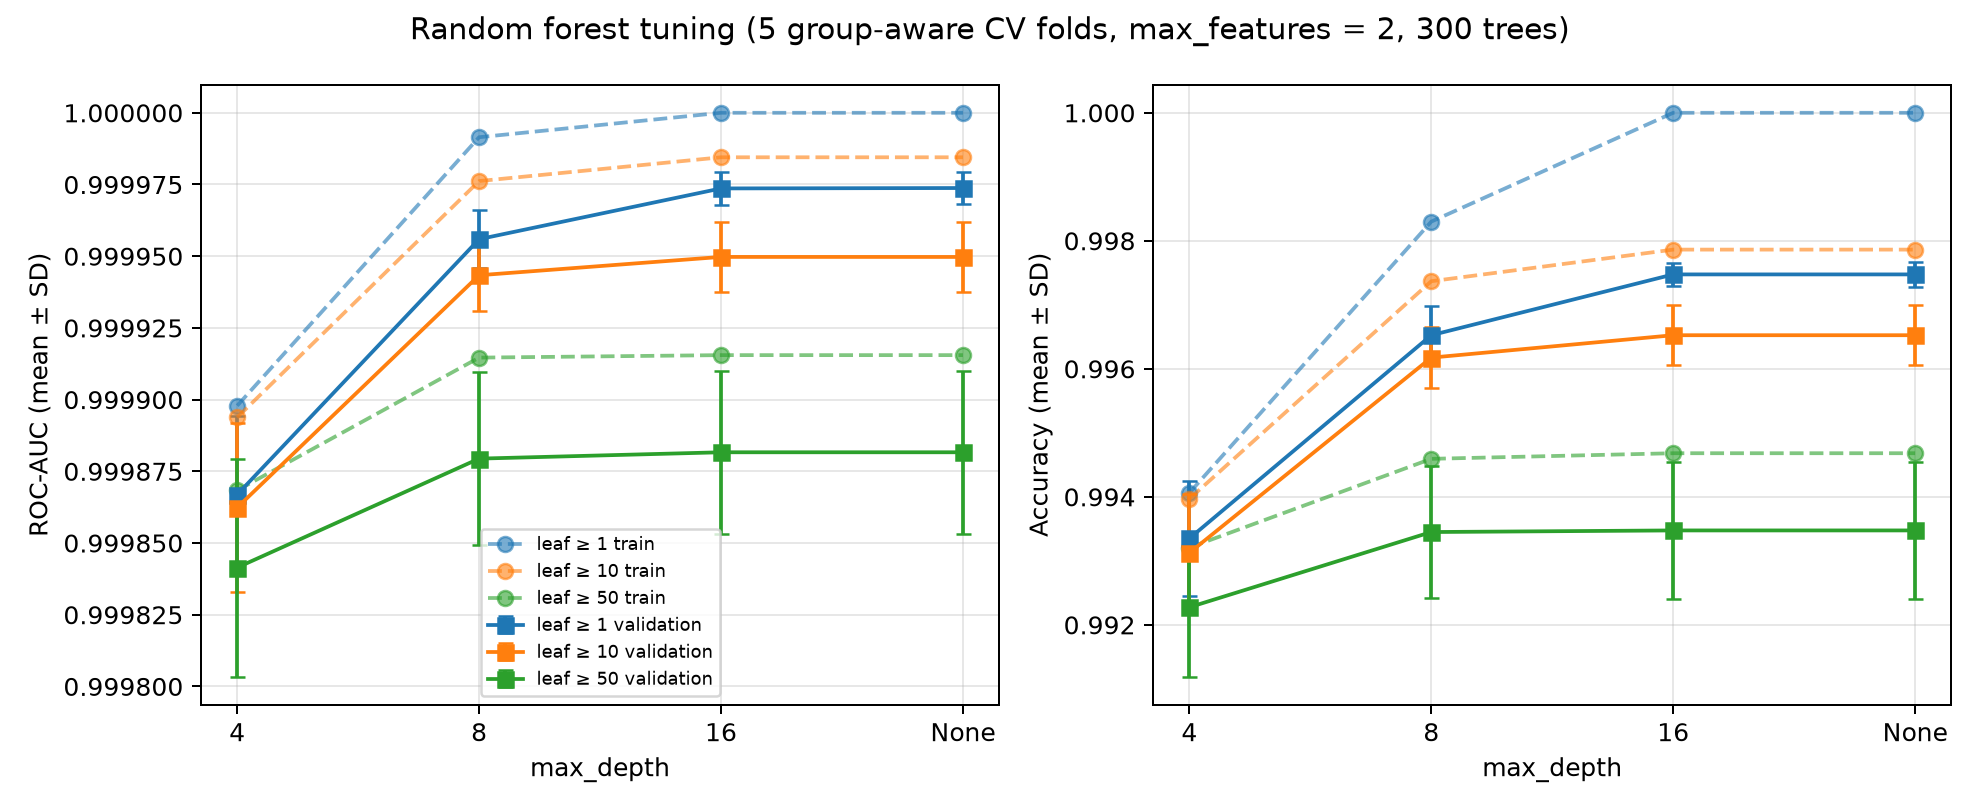

In [4]:
show("random_forest_tuning_curve.png", 900)

## Training vs. validation vs. test

In [5]:
def stage_row(block, part=None):
    return {m: (block[part][m]["mean"] if part else block[m]) for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]}

stages = pd.DataFrame({
    "CV train (mean)": stage_row(results["cv_near_duplicate_groups"], "train"),
    "CV validation (mean)": stage_row(results["cv_near_duplicate_groups"], "validation"),
    "Full training set": stage_row(results["full_train_metrics"]),
    "Held-out test": stage_row(results["test_metrics"]),
    "Unseen template families": stage_row(results["template_family_holdout"]["summary"], "validation"),
}).T.round(4)
stages

,accuracy,precision,recall,f1,roc_auc
CV train (mean),1.0000,1.0000,1.0000,1.0000,1.0000
CV validation (mean),0.9975,0.9974,0.9976,0.9975,1.0000
Full training set,1.0000,1.0000,1.0000,1.0000,1.0000
Held-out test,0.9952,0.9926,0.9978,0.9952,0.9999
Unseen template families,0.9859,0.9886,0.9794,0.9837,0.9984


## Test-set confusion matrix and ROC curve

In [6]:
pd.Series(results["test_confusion_matrix"]).to_frame("rows")

,rows
true_human_pred_human,4963
true_human_pred_ai,37
true_ai_pred_human,11
true_ai_pred_ai,4989


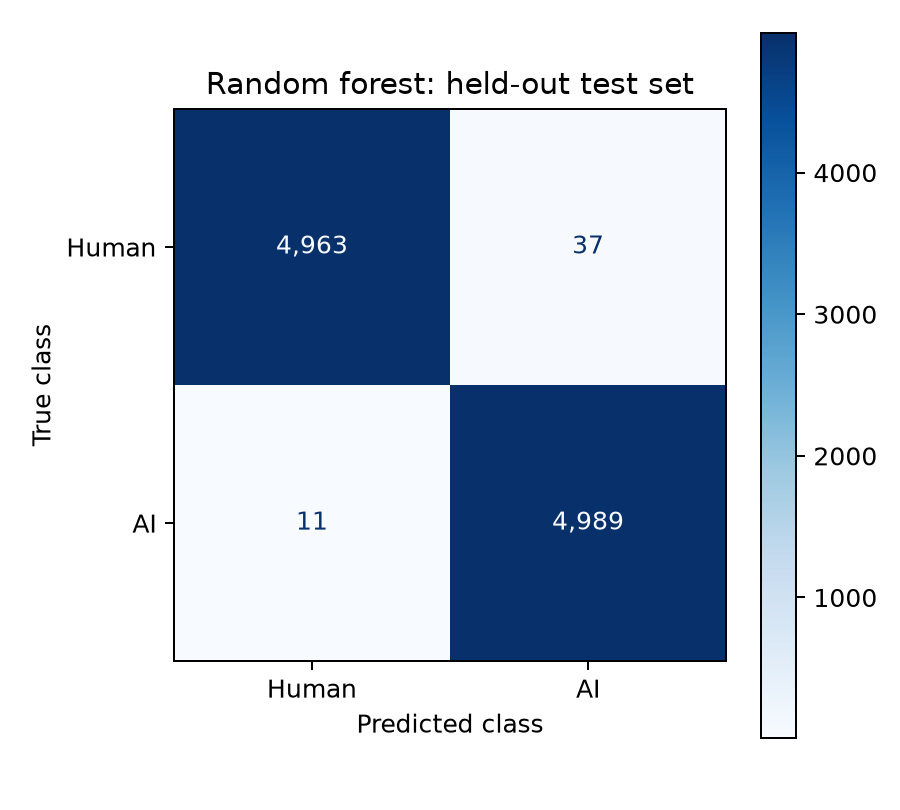

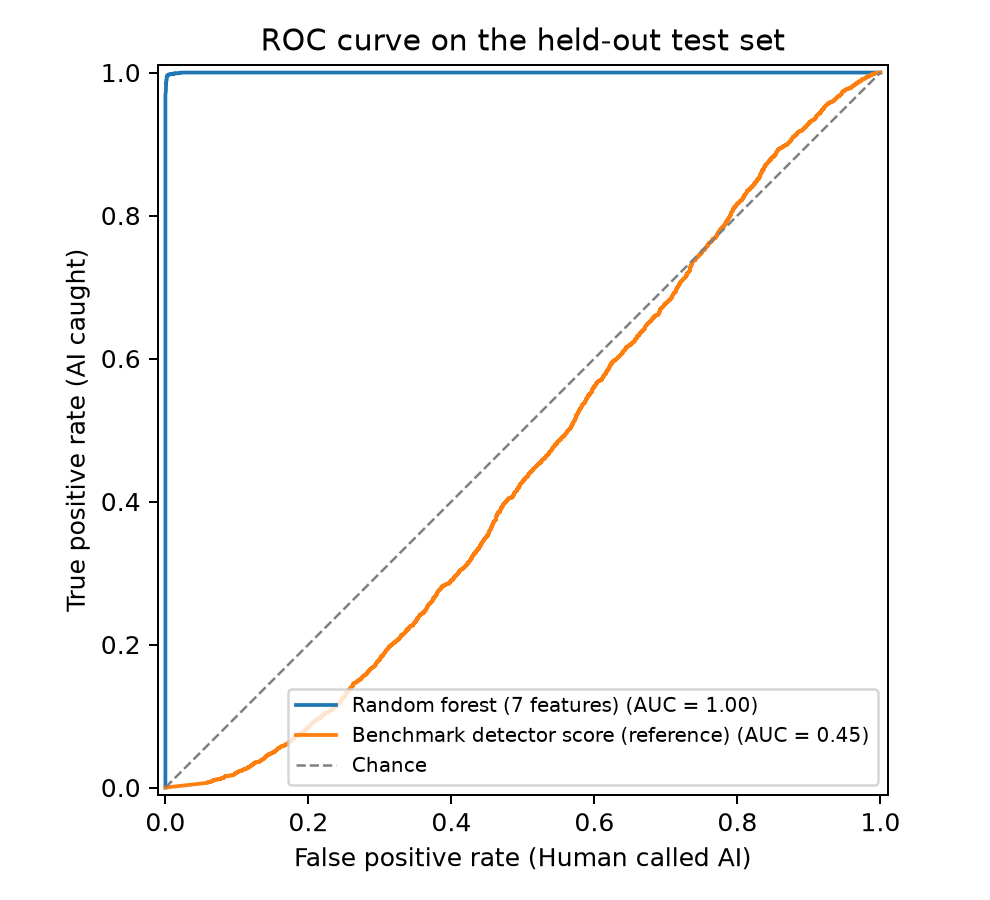

In [7]:
show("random_forest_confusion_matrix.png", 450)
show("random_forest_roc_curve.png", 500)

## Interpretation: feature importance

In [8]:
pd.DataFrame(results["feature_importance"]).T.sort_values("permutation_mean", ascending=False).round(4)

,permutation_mean,permutation_std,impurity
Text_Flesch_Kincaid_Grade_Level,0.1676,0.0028,0.4008
Text_Average_Word_Length,0.0133,0.0005,0.2892
Text_Punctuation_Density,0.0055,0.0002,0.2048
Text_Word_Count,0.0002,0.0000,0.0076
Text_Average_Sentence_Length_Words,0.0001,0.0000,0.0203
Text_Burstiness,0.0001,0.0000,0.0648
Text_Guiraud_Root_TTR,0.0001,0.0000,0.0126


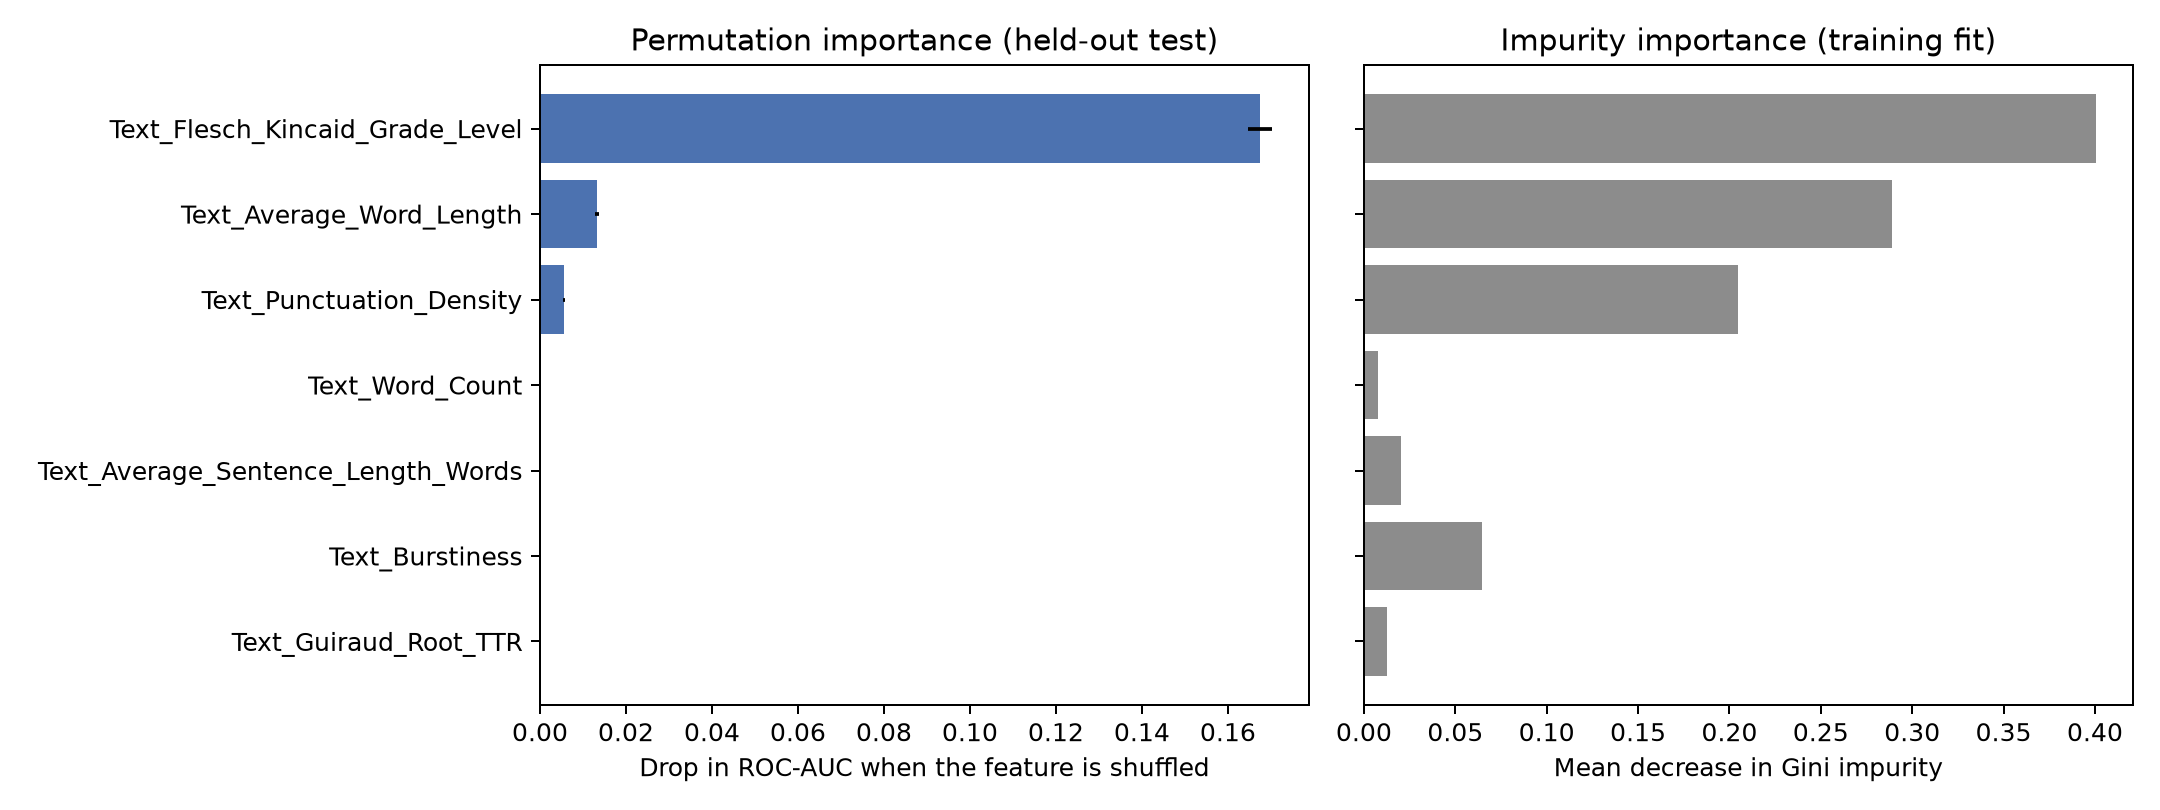

In [9]:
show("random_forest_feature_importance.png", 900)

**Permutation importance** shuffles one feature on the test set and measures how much
ROC-AUC drops. It is measured on held-out data, so it is the more trustworthy view.
Reading grade level dominates, followed by average word length and punctuation density.
These are the same features logistic regression weighted most.
**Impurity importance** is computed on training data and spreads credit across
correlated features, so it overstates features like burstiness.

**Over/underfitting:** the selected forest uses fully grown trees and fits the training
data perfectly (100%), while validation accuracy is 99.75%. That gap is small and typical
for random forests. Validation accuracy still rises with depth, so the extra fit isn't
hurting results on near-duplicate-safe folds. On **unseen templates**, though, the forest
does slightly worse than logistic regression (see notebook 05).

## Stress test: unseen templates

Each fold below holds out whole template families, so the model is scored on writing
styles it never saw during training. This uses the training partition only.

In [10]:
family = results["template_family_holdout"]
pd.DataFrame([
    {**fold, "validation_accuracy": acc}
    for fold, acc in zip(family["folds"], family["summary"]["validation"]["accuracy"]["folds"])
])

,validation_families,validation_rows,validation_ai_proportion,validation_accuracy
0,"[0, 9, 10]",10506,0.390158,0.959737
1,"[1, 8]",7390,0.546414,1.000000
2,"[2, 6]",7407,0.540570,1.000000
3,"[4, 7]",7340,0.536104,0.971662
4,"[3, 5]",7357,0.533370,0.998097


## External reference

The benchmark's own detector score, thresholded at 50, on the same test rows. It is
evaluation-only and never a model input.

In [11]:
pd.Series(results["benchmark_detector_reference_on_test"]).to_frame("value")

,value
note,"Detection_Score_Benchmark_Model_A, thresholded at 50; evaluation only"
accuracy,0.487
precision,0.490154
recall,0.6472
f1,0.557835
roc_auc,0.448033
